# Build Forcing Validation - Temperature
- Tony Grove

In [1]:
%matplotlib ipympl
import pandas as pd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from buildforcing.datasets import PNNLSnotel
from gdriver.gdriver import get_credentials, getCSVtoPandas
import os

In [2]:
# Run parameters
site = 'Tony Grove RS'
latitude = 41.89
longitude = -111.57
start_date = '20150101'
end_date = '20150301'
buildforcing_version = 'v0.1.0'
#environment = '/home/chriscox/Data/'
environment = 'C:/Users/clmbn/NMT_PhD/data/' # Windows

### Load datasets

In [3]:
# Load the forcing dataset
sitename = site.replace(' ', '').lower()
tg_forcing = xr.open_dataset(os.path.join(environment,'forcing',f'{sitename}_{start_date}_{end_date}_{buildforcing_version}.nc'))

In [ ]:
tg_forcing

In [4]:
# Extract Tair from dataset to a pandas dataframe ignoring the lat/lon dimensions
# and keeping the time dimension
forcing_Tair = tg_forcing['Tair'].isel(latitude=0, longitude=0)
forcing_Tair = forcing_Tair.to_dataframe()

In [5]:
# Convert temperature from Kelvin to Celsius
forcing_Tair['Tair_C'] = forcing_Tair['Tair'] - 273.15

In [6]:
forcing_Tair.index = forcing_Tair.index.tz_localize('UTC').tz_convert('America/Denver')

In [7]:
snotel = PNNLSnotel(site_name=site, storage_path=os.path.join(environment, 'snotel'))

In [ ]:
snotel.data.head()

In [8]:
nldas_forcing = xr.open_dataset(os.path.join(environment,'nldas',f'NLDAS_{latitude}_{longitude}_{start_date}_{end_date}.nc'))

In [9]:
nldas_Tair = nldas_forcing['Tair'].to_dataframe()
nldas_Tair['Tair_C'] = nldas_Tair['Tair'] - 273.15
nldas_Tair.index = nldas_Tair.index.tz_localize('UTC').tz_convert('America/Denver')

#### Load GAMUT

In [10]:
# Load gdriver credentials
credentials = get_credentials()

# Get the ST110 data
gamut_st110 = getCSVtoPandas('TonyGrove/LR_TG_C_AirTemp_ST110_Avg_SourceID_1_QC_1.csv',credentials,skiprows=56)

# Change index to DateTimeUTC
gamut_st110['DateTime'] = pd.to_datetime(gamut_st110['LocalDateTime'])
gamut_st110 = gamut_st110.set_index('DateTime')

# Convert -9999 to NaN
gamut_st110 = gamut_st110.replace(-9999, np.nan)

Download 100.


In [11]:
# Extract a subset of the data for the time period of interest
start_date = '2015-01-01 00:00:00'
end_date = '2015-03-01 00:00:00'
gamut_st110_month = gamut_st110.loc[start_date:end_date]

# Localize datetime to america/denver timezone
gamut_st110_month.index = gamut_st110_month.index.tz_localize('America/Denver')

## Comparisons

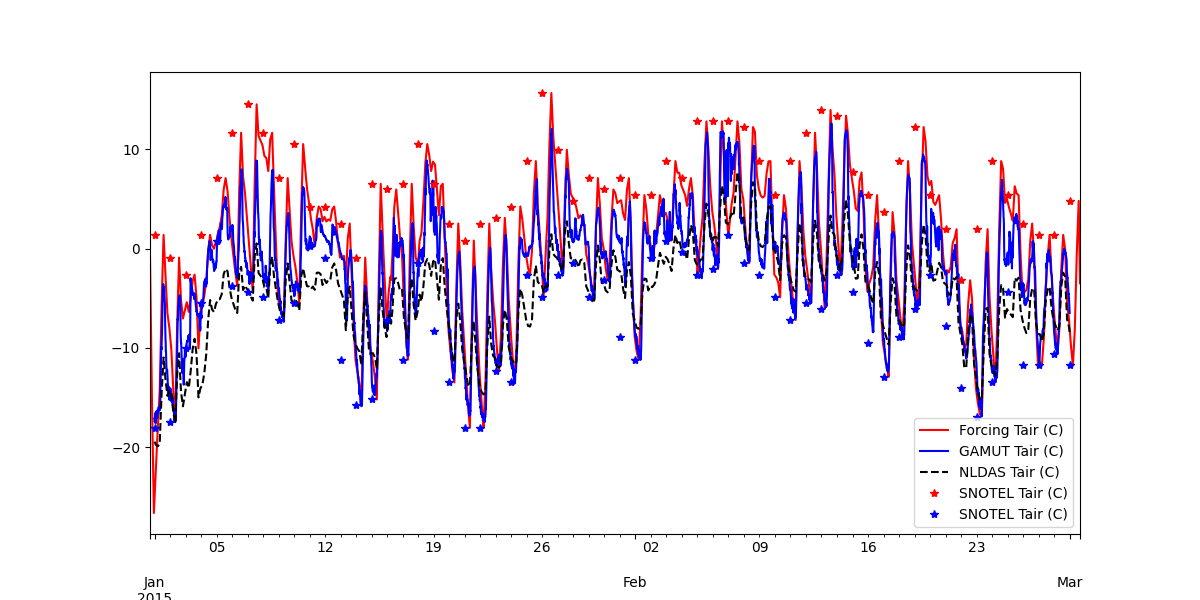

In [24]:
# Plot Tair and compare to ST110 data
fig, ax = plt.subplots(figsize=(12, 6))
forcing_Tair['Tair_C'].plot(ax=ax, label='Forcing Tair (C)', color='r', linestyle='-')
gamut_st110_month['AirTemp_ST110_Avg'].plot(ax=ax, label='GAMUT Tair (C)', color='b', linestyle='-')
nldas_Tair['Tair_C'].loc[start_date:end_date].plot(ax=ax, label='NLDAS Tair (C)', color='k', linestyle='--')
snotel.data.loc[start_date:end_date,'T_max_C'].plot(ax=ax, label='SNOTEL Tair (C)', color='r', marker='*', linestyle='None')
snotel.data.loc[start_date:end_date,'T_min_C'].plot(ax=ax, label='SNOTEL Tair (C)', color='b', marker='*', linestyle='None')
ax.legend()
# fig, ax = plt.subplots(figsize=(12, 6))
# forcing_Tair['Tair_C'].plot(ax=ax, label='Forcing Tair (C)', style='r')
# gamut_st110_month['AirTemp_ST110_Avg'].plot(ax=ax, label='GAMUT Tair (C)', style='b-')
# nldas_Tair['Tair_C'].loc[start_date:end_date].plot(ax=ax, label='NLDAS Tair (C)', style='k--')
# snotel.data.loc[start_date:end_date,'T_max_C'].plot(ax=ax, label='SNOTEL Tair (C)', style='r*')
# snotel.data.loc[start_date:end_date,'T_min_C'].plot(ax=ax, label='SNOTEL Tair (C)', style='b*')
# ax.legend()

#